---
authors:
  - name: Emma Pidduck
    url: https://www.linkedin.com/in/emmapidduck/
---

# Day 15 · Inside out — The ocean, inside out

<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

### #30DayMapChallenge 2026 · ECMWF IFS wave forecast, open data · Map by Emma Pidduck

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

Most world maps are built around the land and cut the ocean wherever it is convenient.
This notebook gives the page to the **ocean** instead, twice, with today's **waves** from the
ECMWF forecast on top: how high the sea is, and which way the waves are travelling.

- **View 1 — Inside out.** The **Spilhaus projection** cuts through the *continents* and keeps
  the ocean in one piece, with Antarctica in the middle and the land pushed out to the frame.
- **View 2 — Africa in the middle.** A **Lambert azimuthal equal-area** disc centred on the Gulf
  of Guinea: a familiar north-up world, with every patch of sea at its true size.

Each view is a poster and a five-day animation, built from the same data by the same
functions — only the canvas changes. A third canvas, centred on the Arctic, is a bonus at the end.

Self-contained: method, code, output, data licence and tools in one place, runnable on any
laptop with `pip`.

## Method

- Fetch **significant wave height** (`swh`) and **mean wave direction** (`mwd`) from the
  ECMWF wave forecast (open data, 0.25°). Significant wave height is roughly the average
  height of the highest third of the waves — close to what an observer at sea would report.
- Turn the map **inside out**: lay a square pixel grid over the projection plane, ask PROJ for
  the longitude/latitude of every pixel (the *inverse* projection), and sample the wave
  field there. No reprojection of polygons, so no seams to repair — and swapping the
  projection is a one-line change.
- **Land is drawn as a void.** The wave model has no values over land (GRIB missing values),
  and where the sea is frozen it reports no waves — so the sea ice appears on its own,
  without a sea-ice dataset.
- Draw short **streaks** along the direction the waves travel. `mwd` is the direction waves
  come *from*, so the streaks follow `mwd + 180°`; each direction is pushed through the
  projection so it stays correct on the distorted map.

Look for the ring of storms around Antarctica: on this map it is obvious that the Southern
Ocean is the hub that connects the Atlantic, Indian and Pacific.

## Data

| Dataset | What is used | Licence |
|---|---|---|
| [ECMWF Open Data](https://www.ecmwf.int/en/forecasts/datasets/open-data) — IFS wave forecast (`stream=wave`), 0.25° | significant wave height `swh`, mean wave direction `mwd`; 00 UTC run, +0 h for the poster and +0 to +120 h for the animation | CC-BY-4.0 |
| [Natural Earth](https://www.naturalearthdata.com) 1:50m physical | land polygons, for a crisp coastline | public domain |

No account needed for either.

## Licence & attribution

Access to ECMWF Open Data is governed by the **Creative Commons CC-BY-4.0** licence and the
associated [Terms of Use](https://apps.ecmwf.int/datasets/licences/general/).

> In applying this licence, ECMWF does not waive the privileges and immunities granted to it
> by virtue of its status as an intergovernmental organisation.

When you share a map made from this data, attribute it:
`© ECMWF · Source: www.ecmwf.int · Licence: CC-BY-4.0 and ECMWF Terms of Use`

Coastlines: [Natural Earth](https://www.naturalearthdata.com) (public domain).

## Tools

| Tool | Role |
|---|---|
| [`ecmwf-opendata`](https://github.com/ecmwf/ecmwf-opendata) | retrieve the IFS wave forecast (the ECMWF API client) |
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | read & handle the GRIB (modern ECMWF stack) |
| [`pyproj`](https://pyproj4.github.io/pyproj/) | the projections: `spilhaus` (needs **PROJ ≥ 9.6**), `laea`, `aeqd` |
| `scipy`, `Pillow` | resampling, and rasterising the Natural Earth land mask |
| `cartopy` | only used to download the Natural Earth land polygons |
| [`cmcrameri`](https://www.fabiocrameri.ch/colourmaps/) | `lapaz` — a perceptually-uniform, colourblind-safe ramp |

| `Pillow` · `ffmpeg` (optional) | the GIF · a crisper MP4 |

```bash
pip install ecmwf-opendata earthkit-data cfgrib xarray pandas pyproj scipy pillow cartopy cmcrameri matplotlib
```

One gotcha: cartopy has no Spilhaus projection class, so all the maps are drawn as images with
plain matplotlib. `pyproj.proj_version_str` tells you which PROJ you have.

**Learn more:** [ECMWF Open Data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [ocean wave parameters](https://confluence.ecmwf.int/display/FUG/Section+2.2+Ocean+Wave+Model+-+ECWAM) · [Spilhaus in PROJ](https://proj.org/en/stable/operations/projections/spilhaus.html) · [scientific colour maps](https://www.fabiocrameri.ch/colourmaps/)

In [1]:
# Run once if needed (uncomment):
#!pip install ecmwf-opendata earthkit-data cfgrib xarray pandas pyproj scipy pillow cartopy cmcrameri matplotlib

In [2]:
import os, sys, io, contextlib
import numpy as np
import xarray as xr
import pyproj
import earthkit.data as ekd
from ecmwf.opendata import Client
from scipy import ndimage as ndi
import pandas as pd
from types import SimpleNamespace
from PIL import Image, ImageDraw
import cartopy.io.shapereader as shpreader
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.patheffects as pe
from matplotlib.colors import to_rgb, to_rgba, ListedColormap
from matplotlib.collections import LineCollection
from cmcrameri import cm as cmc

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
print("PROJ", pyproj.proj_version_str)

@contextlib.contextmanager
def quiet():
    """Silence the open-data banner + download progress bars. Real errors still raise."""
    py = sys.stderr; sys.stderr = io.StringIO()
    try:
        saved = os.dup(2); dn = os.open(os.devnull, os.O_WRONLY); os.dup2(dn, 2)
    except Exception:
        saved = None
    try:
        yield
    finally:
        sys.stderr = py
        if saved is not None:
            os.dup2(saved, 2); os.close(saved); os.close(dn)

PROJ 9.8.1


### Configuration

`DATE = 0` pulls **today's** 00Z run, so re-running on **15 November 2026** produces that
day's ocean with no edits. Pin a specific day with e.g. `DATE = "20261115"` (delete the
GRIB file first, or change its name, to force a new download).

In [3]:
DATE, TIME, STEP = 0, 0, 0                   # today 00Z, analysis step
GRIB   = "data/day15_waves.grib2"
OUTPNG = "day15_inside_out.png"
AUTHOR = "Emma Pidduck"
N      = 2400                                # poster map size in pixels
VMAX   = 8.0                                 # top of the colour scale, metres
BG, INK, MUT, ICE = "#0d0f12", "#ece6dc", "#8a9099", "#c9d6dc"
FRAME  = "#5a626c"                           # thin border around the map
LAND_DISC = "#1d2228"                        # on the disc maps, land a shade lighter than the page
R_EARTH = 6371008.8                          # metres

## Retrieve

Two parameters from the wave stream:
[swh = 140229](https://codes.ecmwf.int/grib/param-db/140229) and
[mwd = 140230](https://codes.ecmwf.int/grib/param-db/140230). Downloaded to a file so
re-runs are reproducible and offline-friendly.

In [4]:
os.makedirs("data", exist_ok=True)
with quiet():
    if not os.path.exists(GRIB):
        Client("ecmwf").retrieve(date=DATE, time=TIME, step=STEP, stream="wave", type="fc",
                                 param=["swh", "mwd"], target=GRIB)

## Reading & processing

Read the GRIB with **earthkit-data**. The grid is 0.25°, latitude 90 → −90, longitude
−180 → 179.75. Three kinds of point matter:

- **open sea** — a wave height;
- **land** — GRIB *missing value* (`NaN`);
- **sea ice** — the wave model reports the field minimum (no waves), so ice is
  "ocean with a wave height of zero, at high latitude".

In [5]:
x   = ekd.from_source("file", GRIB).to_xarray().squeeze()
lat = x["latitude"].values; lon = x["longitude"].values
swh = x["swh"].values; mwd = x["mwd"].values
assert lat[0] > lat[-1] and lon[0] == -180.0, "unexpected grid orientation"
DLAT = abs(lat[1] - lat[0]); NLAT, NLON = swh.shape

VALID = pd.Timestamp(xr.open_dataset(GRIB, engine="cfgrib")["valid_time"].values)
missing = np.isnan(swh)                       # land: the same points at every forecast step
NEAR  = ndi.distance_transform_edt(missing, return_distances=False, return_indices=True)
FLOOR = np.nanmin(swh) + 0.005                # "no waves" = sea ice
imax = np.unravel_index(np.nanargmax(swh), swh.shape)
MAXV, MAXLAT, MAXLON = float(swh[imax]), float(lat[imax[0]]), float(lon[imax[1]])
print(f"grid {swh.shape} at {DLAT:.2f} deg   valid {VALID:%Y-%m-%d %H:%M} UTC")
print(f"missing (land) {missing.mean():.0%}   highest seas {MAXV:.1f} m at {MAXLAT:.2f}N {MAXLON:.2f}E")

grid (721, 1440) at 0.25 deg   valid 2026-11-10 00:00 UTC
missing (land) 36%   highest seas 9.3 m at 57.25N -140.00E


### Turn the map inside out

The Spilhaus plane is a square about ±11 830 km across. For every pixel we ask PROJ the
*inverse* question — "which longitude/latitude lands here?" — and keep the answer as a
**canvas** that any field can be sampled onto. `pix()` goes the other way, for placing labels.

The 0.25° model land mask is too blocky for a poster, so the coast comes from
**Natural Earth 50 m** land polygons, rasterised at 0.05° and looked up through the same
inverse projection.

In [6]:
P = pyproj.Proj("+proj=spilhaus")
L = 11.83e6                                                   # half-width of the square, metres

S = 20; W_, H_ = 360 * S, 180 * S                             # 0.05 deg land raster
img = Image.new("L", (W_, H_), 0); drw = ImageDraw.Draw(img)
ring = lambda cs: [((px + 180) * S, (90 - py) * S) for px, py in cs]
for geom in shpreader.Reader(shpreader.natural_earth("50m", "physical", "land")).geometries():
    for poly in getattr(geom, "geoms", [geom]):
        drw.polygon(ring(poly.exterior.coords), fill=1)
        for hole in poly.interiors:
            drw.polygon(ring(hole.coords), fill=0)
LAND_RASTER = np.asarray(img)

def make_canvas(n, proj=P, half=L, rmax=None):
    "An n x n pixel grid over a square of the projection plane, with the lon/lat of every pixel."
    xs = np.linspace(-half, half, n)
    X, Y = np.meshgrid(xs, xs[::-1])                          # row 0 = top of the map
    plon, plat = proj(X, Y, inverse=True)
    valid = np.isfinite(plon) & np.isfinite(plat)             # a sliver at the corners is outside
    if rmax is not None: valid &= np.hypot(X, Y) <= rmax      # for projections that draw the world as a disc
    plon = np.where(valid, plon, 0.0); plat = np.where(valid, plat, 0.0)
    r = (90.0 - plat) / DLAT                                  # fractional row/column in the 0.25 deg grid
    c = ((plon + 180.0) % 360.0) / DLAT
    ne_land = LAND_RASTER[np.clip(((90 - plat) * S).astype(int), 0, H_ - 1),
                          np.clip(((plon + 180) * S).astype(int), 0, W_ - 1)] == 1
    return SimpleNamespace(n=n, proj=proj, half=half, plon=plon, plat=plat, valid=valid, r=r, c=c, ne_land=ne_land,
                           ri=np.clip(np.rint(r).astype(int), 0, NLAT - 1), ci=np.rint(c).astype(int) % NLON)

def pix(g, lo, la):
    "lon/lat -> pixel (column, row) on canvas g."
    px, py = g.proj(lo, la)
    return (px + g.half) / (2 * g.half) * (g.n - 1), (g.half - py) / (2 * g.half) * (g.n - 1)

def wave_height(g, field):
    "Fill the land with the nearest sea value, then interpolate smoothly up to the coast."
    f = field[tuple(NEAR)]
    return ndi.map_coordinates(np.concatenate([f, f[:, :1]], axis=1), [g.r, g.c], order=1, mode="nearest")

def sea_ice(g, field):
    raw = field[g.ri, g.ci]                                   # un-interpolated, to classify pixels
    nowave = (raw < FLOOR) | (np.isnan(raw) & (g.plat > 80))  # the grid stops just short of the North Pole
    return nowave & ~g.ne_land & (np.abs(g.plat) > 50) & g.valid

def land_mask(g, field, ice):
    land = (g.ne_land | np.isnan(field[g.ri, g.ci]) | ~g.valid) & ~ice   # incl. Antarctic ice shelves, lakes
    return ndi.binary_opening(land, iterations=1) | g.ne_land | ~g.valid  # drop 1-pixel specks

G = make_canvas(N)
H = wave_height(G, swh); ice = sea_ice(G, swh); land = land_mask(G, swh, ice)
print(f"land {land.mean():.0%} · sea ice {ice.mean():.1%} · open sea {(~land & ~ice).mean():.0%} of the square")

land 53% · sea ice 1.5% · open sea 46% of the square


### Which way are the waves going?

A compass direction is not a direction on a distorted map. For each pixel we take a small
step along the wave's direction of travel on the sphere, project both ends, and keep the
resulting unit vector in pixel space. Then ~15 000 random seeds are advected a few steps
through that field to make the streaks.

In [7]:
K = 4                                                         # direction field at 1/4 of the canvas resolution

def direction(g, mwd_field, eps=0.05):
    "Unit vectors (U, V) in pixel space for the direction the waves travel TOWARD."
    theta = np.deg2rad(mwd_field[tuple(NEAR)] + 180.0)
    sub = (slice(None, None, K), slice(None, None, K))
    ue, vn = np.sin(theta)[g.ri, g.ci][sub], np.cos(theta)[g.ri, g.ci][sub]   # east, north
    lo, la = g.plon[sub], g.plat[sub]
    x0, y0 = g.proj(lo, la)
    x1, y1 = g.proj(lo + eps * ue / np.maximum(np.cos(np.deg2rad(la)), 0.05), np.clip(la + eps * vn, -89.9, 89.9))
    dx, dy = x1 - x0, y1 - y0; norm = np.hypot(dx, dy)
    bad = ~np.isfinite(norm) | (norm == 0) | (norm > 3 * np.nanmedian(norm))   # steps across the map's cut
    return np.where(bad, 0, dx / np.where(bad, 1, norm)), np.where(bad, 0, -dy / np.where(bad, 1, norm))

def advect(g, U, V, sx, sy, step_px):
    iy = np.clip((sy / K).astype(int), 0, U.shape[0] - 1); ix = np.clip((sx / K).astype(int), 0, U.shape[1] - 1)
    return np.clip(sx + step_px * U[iy, ix], 0, g.n - 1), np.clip(sy + step_px * V[iy, ix], 0, g.n - 1)

def streaks(g, U, V, H, land, ice, seeds=42000, steps=26, step_px=1.6, rng_seed=15):
    "Short polylines following the wave direction, and the wave height at the start of each."
    rng = np.random.default_rng(rng_seed)
    sx = rng.uniform(0, g.n - 1, seeds); sy = rng.uniform(0, g.n - 1, seeds)
    sea = ~land[sy.astype(int), sx.astype(int)] & ~ice[sy.astype(int), sx.astype(int)]
    sx, sy = sx[sea], sy[sea]
    path = np.empty((steps, sx.size, 2)); alive = np.ones(sx.size, bool)
    for s in range(steps):
        path[s, :, 0] = sx; path[s, :, 1] = sy
        sx, sy = advect(g, U, V, sx, sy, step_px)
        alive &= ~land[sy.astype(int), sx.astype(int)]        # drop streaks that run ashore
    segs = path.transpose(1, 0, 2)[alive]
    return segs, H[segs[:, 0, 1].astype(int), segs[:, 0, 0].astype(int)]

U, V = direction(G, mwd)
segs, seg_h = streaks(G, U, V, H, land, ice)
print(f"{len(segs)} streaks")

15561 streaks


### Colour — and why it is colourblind-safe

Wave height is a *sequential* quantity, so it wants a sequential ramp: **`lapaz`** from
Fabio Crameri's scientific colour maps (deep blue → pale sand), trimmed slightly at both
ends so the calmest sea stays distinct from the black land. The cell **validates** that it
is monotonic in luminance — it reads correctly for every form of colour-vision deficiency
and in greyscale.

In [8]:
CMAP = ListedColormap(cmc.lapaz(np.linspace(0.08, 0.97, 256)))

def luminance_monotonic(cmap, n=256):
    rgb = np.array([to_rgba(cmap(t))[:3] for t in np.linspace(0, 1, n)])
    lum = 0.2126*rgb[:,0] + 0.7152*rgb[:,1] + 0.0722*rgb[:,2]   # relative luminance
    d = np.diff(lum)
    return (d >= -1e-3).all() or (d <= 1e-3).all(), lum

ok, lum = luminance_monotonic(CMAP)
print(f"luminance-monotonic: {ok}   (luminance {lum[0]:.2f} -> {lum[-1]:.2f})")

def colourise(H, ice, land, land_colour=BG):
    rgb = CMAP(np.clip(H / VMAX, 0, 1))[..., :3]
    rgb[ice] = to_rgb(ICE); rgb[land] = to_rgb(land_colour)
    return rgb

luminance-monotonic: True   (luminance 0.16 -> 0.93)


## View 1 — Inside out (Spilhaus)

The map sits in a thin frame — the ocean really is cut at the edge of the Spilhaus square
in a few places (the Bering Strait, Central America), and the frame makes that deliberate.
The text sits in the land, which on this projection is the empty part. The highest seas of
the day are ringed and labelled automatically, so the poster stays correct on whichever day
it is run.

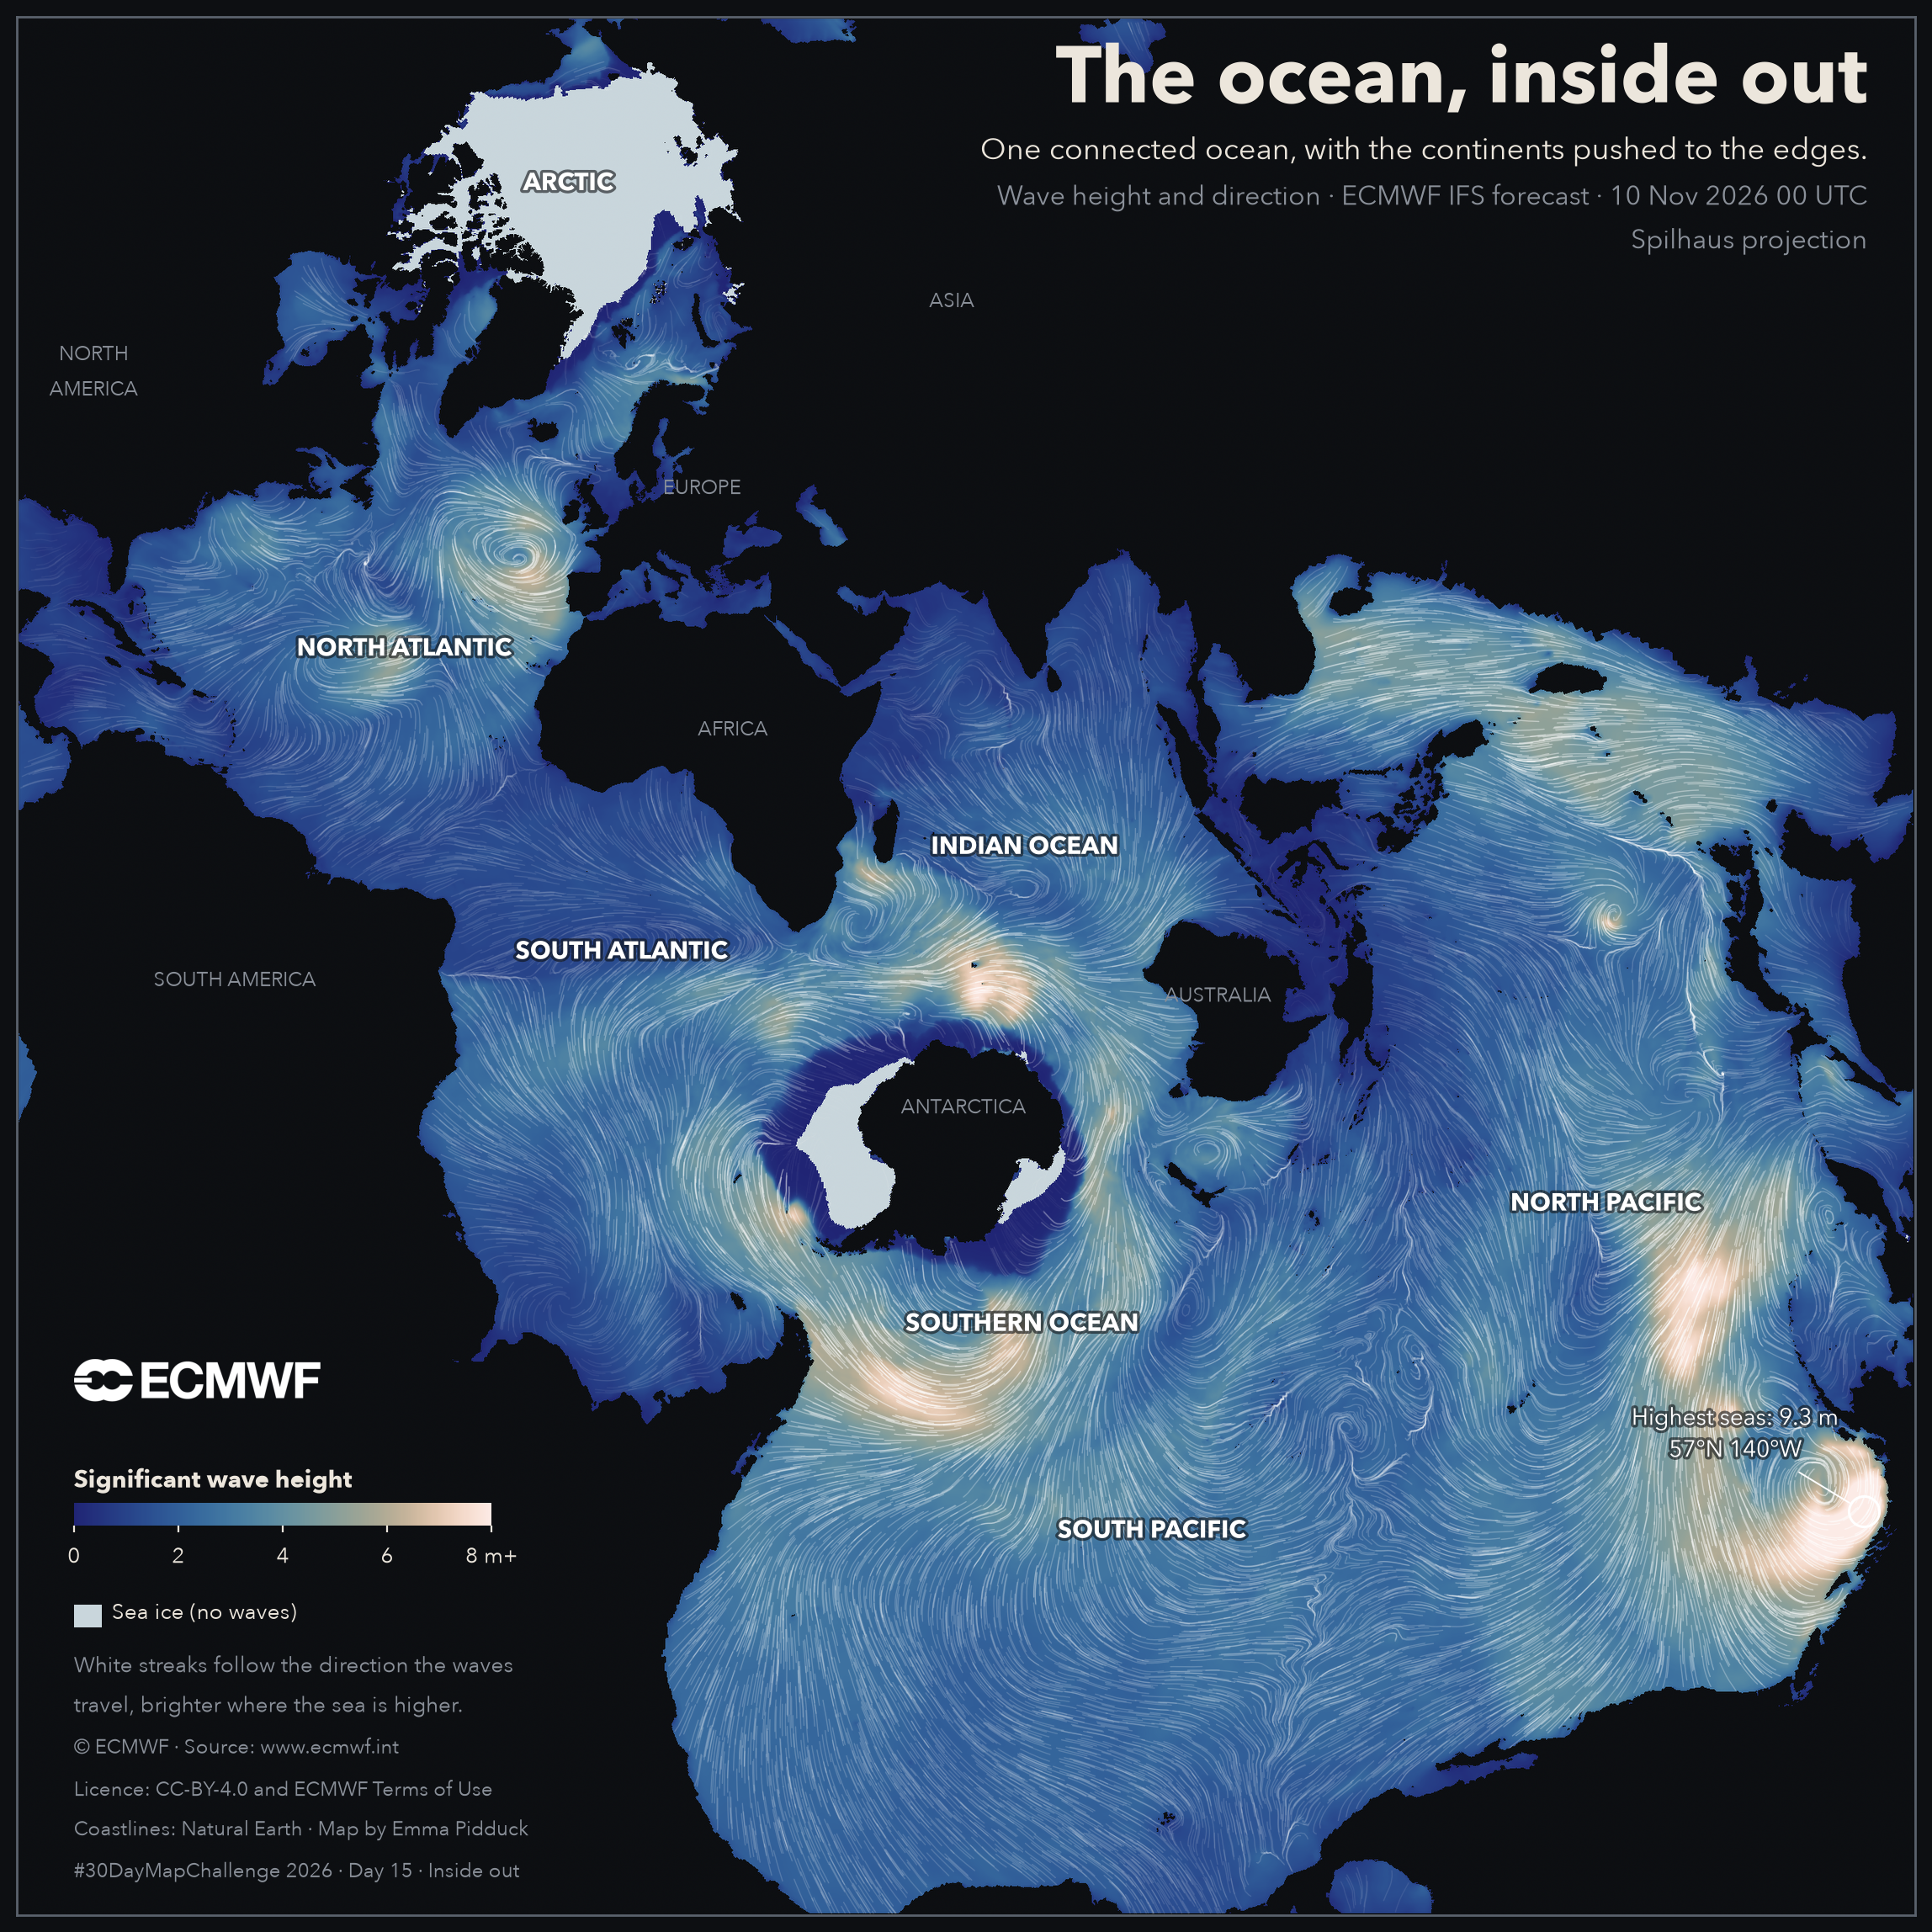

In [9]:
OCEANS = [("NORTH ATLANTIC", -40, 30), ("SOUTH ATLANTIC", -15, -22), ("INDIAN OCEAN", 78, -22),
          ("SOUTH PACIFIC", -118, -22), ("NORTH PACIFIC", 172, 28), ("SOUTHERN OCEAN", -125, -58),
          ("ARCTIC", -150, 82)]
LANDS  = [("AFRICA", 20, 10), ("EUROPE", 28, 54), ("ASIA", 95, 50), ("NORTH\nAMERICA", -96, 42),
          ("SOUTH AMERICA", -58, -10), ("AUSTRALIA", 130, -26), ("ANTARCTICA", 75, -80)]
HALO = [pe.withStroke(linewidth=2.4, foreground=BG, alpha=0.6)]
M = 0.03                                                      # margin around the framed map
fx = lambda v: M + (1 - 2 * M) * v                            # square-canvas coords -> figure coords
lh = lambda pts, spacing=1.5: pts * spacing / 864 / (1 - 2 * M)   # height of a text line, canvas coords (12 in figure)

def base(g, rgb, oceans, lands, dpi=200, fs=1.0):
    "The framed map with ocean and continent labels. fs scales every font (the animation uses bigger type)."
    fig = plt.figure(figsize=(12, 12), dpi=dpi, facecolor=BG)
    ax = fig.add_axes([M, M, 1 - 2 * M, 1 - 2 * M]); im = ax.imshow(rgb, interpolation="lanczos")
    ax.set_xlim(0, g.n - 1); ax.set_ylim(g.n - 1, 0); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_edgecolor(FRAME); sp.set_linewidth(1.0)
    for name, lo, la in oceans:
        px, py = pix(g, lo, la)
        ax.text(px, py, name, color="white", fontsize=10.5 * fs, fontweight="bold", ha="center", va="center",
                path_effects=HALO, zorder=5)
    for name, lo, la in lands:
        px, py = pix(g, lo, la)
        ax.text(px, py, name, color=MUT, fontsize=8.5 * fs, ha="center", va="center", linespacing=1.3)
    return fig, ax, im

def title_block(fig, x, y, ha, title, lines, fs=1.0):
    "Title with up to three lines under it; returns the text objects of the lines."
    fig.text(fx(x), fx(y), title, fontsize=34 * fs, fontweight="bold", color=INK, ha=ha)
    out = []
    for k, (txt, dy) in enumerate(zip(lines, (0.030, 0.054, 0.077))):
        out.append(fig.text(fx(x), fx(y - dy * fs), txt, fontsize=(13 if k == 0 else 11.5) * fs,
                            color=INK if k == 0 else MUT, ha=ha))
    return out

def legend_block(fig, x, y, fs=1.0, note=True, logo=True):
    "Credits, colour bar, sea-ice key and logo, stacked upward from (x, y)."
    credits = ("© ECMWF · Source: www.ecmwf.int\nLicence: CC-BY-4.0 and ECMWF Terms of Use\n"
               f"Coastlines: Natural Earth · Map by {AUTHOR}\n#30DayMapChallenge 2026 · Day 15 · Inside out")
    fig.text(fx(x), fx(y), credits, fontsize=8.8 * fs, color=MUT, linespacing=1.5)
    y += 4 * lh(8.8 * fs) + 0.022
    if note:
        fig.text(fx(x), fx(y), "White streaks follow the direction the waves\ntravel, brighter where the sea is higher.",
                 fontsize=9.5 * fs, color=MUT, linespacing=1.4)
        y += 2 * lh(9.5 * fs, 1.4) + 0.012
    sw = 0.012 * fs
    fig.patches.append(plt.Rectangle((fx(x), fx(y)), 0.014 * fs, (1 - 2 * M) * sw, transform=fig.transFigure,
                                     fc=ICE, ec="none"))
    fig.text(fx(x + 0.02 * fs), fx(y), "Sea ice (no waves)", fontsize=9.5 * fs, color=INK, va="bottom")
    y += sw + 0.012 + lh(9.5 * fs) + 0.012 * fs               # room for the colour-bar tick labels
    cax = fig.add_axes([fx(x), fx(y), (1 - 2 * M) * 0.22 * fs, (1 - 2 * M) * 0.012 * fs])
    cax.imshow(np.linspace(0, 1, 256)[None, :], aspect="auto", cmap=CMAP, extent=[0, VMAX, 0, 1])
    cax.set_yticks([]); cax.set_xticks([0, 2, 4, 6, 8]); cax.set_xticklabels(["0", "2", "4", "6", "8 m+"])
    cax.tick_params(colors=INK, labelsize=9.5 * fs, length=3)
    for sp in cax.spines.values(): sp.set_visible(False)
    y += 0.012 * fs + 0.008
    fig.text(fx(x), fx(y), "Significant wave height", fontsize=10.5 * fs, color=INK, fontweight="bold")
    y += lh(10.5 * fs) + 0.012
    if logo: add_logo(fig, x, y, fs)

def add_logo(fig, x, y, fs=1.0, anchor="W"):
    path = "assets/ECMWF_Core_Logo_WHITE.png"
    if os.path.exists(path):
        a = fig.add_axes([fx(x), fx(y), (1 - 2 * M) * 0.13 * fs, (1 - 2 * M) * 0.05 * fs])
        a.imshow(mpimg.imread(path)); a.set_anchor(anchor); a.axis("off")

def add_streaks(ax, segs, seg_h, lw=0.5):
    cols = np.ones((len(segs), 4)); cols[:, 3] = np.clip(seg_h / 6, 0.06, 1) * 0.5   # brighter in high seas
    ax.add_collection(LineCollection(segs, colors=cols, linewidths=lw, capstyle="round"))

def mark_highest(ax, g, pull=190):
    "Ring + label on the highest seas of the day, with the label pulled toward the middle of the map."
    mx, my = pix(g, MAXLON, MAXLAT)
    vx, vy = g.n / 2 - mx, g.n / 2 - my; vlen = np.hypot(vx, vy) or 1.0
    ax.plot(mx, my, "o", ms=13, mfc="none", mec="white", mew=1.1)
    where = f"{abs(MAXLAT):.0f}°{'N' if MAXLAT >= 0 else 'S'} {abs(MAXLON):.0f}°{'E' if MAXLON >= 0 else 'W'}"
    ax.annotate(f"Highest seas: {MAXV:.1f} m\n{where}", (mx, my),
                xytext=(mx + pull * vx / vlen, my + pull * vy / vlen), textcoords="data",
                color="white", fontsize=10, ha="center", va="center", path_effects=HALO,
                arrowprops=dict(arrowstyle="-", color="white", lw=0.7, shrinkB=7))

SUBTITLE = f"Wave height and direction · ECMWF IFS forecast · {VALID:%-d %b %Y %H} UTC"
fig, ax, _ = base(G, colourise(H, ice, land), OCEANS, LANDS)
add_streaks(ax, segs, seg_h); mark_highest(ax, G)
title_block(fig, 0.975, 0.955, "right", "The ocean, inside out",        # top right: Asia
            ["One connected ocean, with the continents pushed to the edges.", SUBTITLE, "Spilhaus projection"])
legend_block(fig, 0.03, 0.02)                                           # bottom left: the Americas
fig.savefig(OUTPNG, facecolor=BG)
plt.show()

### View 1 in motion

The poster is one instant. Here are the next **five days** of the same forecast
(+0 to +120 h, 3-hourly, with one in-between frame blended from each pair). The type is larger than on the poster, because
video is watched small. The streaks become particles: each one drifts along the wave direction, leaves a short trail, and is
re-seeded somewhere else when it gets old or runs ashore. Their speed is cosmetic — it
shows direction, not how fast the waves travel.

Watch the storms circle Antarctica, and the swell they throw north into all three basins.

In [10]:
ANIM_GRIB = "data/day15_waves_anim.grib2"
ANIM_STEPS = list(range(0, 121, 3))
NA, SUBF, FPS = 1350, 2, 12                  # canvas pixels, frames per 3 h, frames per second
ADPI, AFS = 120, 1.25                        # 12 in x 120 dpi = 1440 px frames; type 25 % larger than the poster
TRAIL, LIFE, SPEED = 14, 34, 1.4             # trail length (frames), particle lifetime, pixels per frame

with quiet():
    if not os.path.exists(ANIM_GRIB):
        Client("ecmwf").retrieve(date=DATE, time=TIME, step=ANIM_STEPS, stream="wave", type="fc",
                                 param=["swh", "mwd"], target=ANIM_GRIB)
da = xr.open_dataset(ANIM_GRIB, engine="cfgrib").sortby("step")
times = pd.to_datetime(da["valid_time"].values); base_t = times[0]
print(f"{da.sizes['step']} forecast steps, {base_t:%Y-%m-%d %H} UTC -> {times[-1]:%Y-%m-%d %H} UTC")

def step_fields(g):
    "Land (fixed) and, for every forecast step, wave height, sea ice and direction on canvas g."
    f0 = da["swh"].values[0]; land = land_mask(g, f0, sea_ice(g, f0))
    out = []
    for k in range(da.sizes["step"]):
        f = da["swh"].values[k]
        out.append((wave_height(g, f), sea_ice(g, f) & ~land, *direction(g, da["mwd"].values[k])))
    return land, out

def paint(g, H, ice, land, land_colour=BG):
    rgb = colourise(H, ice, land, land_colour); rgb[~g.valid] = to_rgb(BG)
    return rgb

41 forecast steps, 2026-11-10 00 UTC -> 2026-11-15 00 UTC


In [11]:
import shutil, subprocess, tempfile

def animate(g, land, fields, ax, im, clock, land_colour=BG, n_particles=14000):
    "Advance particles through the forecast and return the rendered frames. `clock` is the text that shows the time."
    fig = ax.figure; rng = np.random.default_rng(15)

    def seed(m):                                              # m random points on open sea
        out = np.empty((0, 2))
        while len(out) < m:
            q = rng.uniform(0, g.n - 1, (2 * m, 2))
            out = np.vstack([out, q[~land[q[:, 1].astype(int), q[:, 0].astype(int)]]])
        return out[:m]

    pos = seed(n_particles); age = rng.integers(0, LIFE, n_particles)
    trail = np.repeat(pos[None], TRAIL, axis=0)              # [TRAIL, particle, xy], newest last
    lc = LineCollection([], linewidths=0.65, capstyle="round"); ax.add_collection(lc)
    frames = []
    nfr = (len(fields) - 1) * SUBF + 1
    for i in range(-2 * TRAIL, nfr):                          # negative i = spin-up on the first field
        k, w = divmod(max(i, 0), SUBF); w = w / SUBF
        a = fields[k]; b = fields[min(k + 1, len(fields) - 1)]
        Hf = (1 - w) * a[0] + w * b[0]; icef = a[1] if w < 0.5 else b[1]
        Uf = (1 - w) * a[2] + w * b[2]; Vf = (1 - w) * a[3] + w * b[3]

        for _ in range(2):                                    # two small steps per frame = smoother curves
            x_, y_ = advect(g, Uf, Vf, pos[:, 0], pos[:, 1], SPEED)
            moved = np.hypot(x_ - pos[:, 0], y_ - pos[:, 1]) > 0.2
            pos = np.column_stack([x_, y_])
        age += 1
        yi, xi = pos[:, 1].astype(int), pos[:, 0].astype(int)
        dead = (age > LIFE) | land[yi, xi] | icef[yi, xi] | ~moved
        trail = np.roll(trail, -1, axis=0); trail[-1] = pos
        if dead.any():
            pos[dead] = seed(dead.sum()); age[dead] = 0; trail[:, dead] = pos[dead]
        if i < 0:
            continue                                          # trails still growing: do not record

        fade = np.clip(np.minimum(age, LIFE - age) / 8, 0, 1)   # fade in and out, so nothing pops
        hh = Hf[pos[:, 1].astype(int), pos[:, 0].astype(int)]
        cols = np.ones((n_particles, 4)); cols[:, 3] = np.clip(hh / 6, 0.08, 1) * 0.45 * fade
        lc.set_segments(trail.transpose(1, 0, 2)); lc.set_color(cols)
        im.set_data(paint(g, Hf, icef, land, land_colour))
        now = base_t + pd.Timedelta(hours=3 * (k + w))
        clock.set_text(f"{now:%a %-d %b · %H:%M} UTC")
        fig.canvas.draw()
        frames.append(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy())
    plt.close(fig)
    return frames

def write_anim(frames, gif_path, mp4_path):
    "GIF with Pillow (one shared palette, so colours do not flicker); MP4 too if ffmpeg is installed."
    small = [Image.fromarray(f).resize((720, 720), Image.LANCZOS) for f in frames]
    pal = small[len(small) // 2].quantize(colors=256, method=Image.Quantize.MEDIANCUT)
    gif = [s.quantize(palette=pal, dither=Image.Dither.NONE) for s in small]   # no dither: far smaller file
    dur = [1000 // FPS] * len(gif); dur[-1] = 1800           # hold the last frame
    gif[0].save(gif_path, save_all=True, append_images=gif[1:], duration=dur, loop=0, optimize=True)
    print(f"{gif_path}: {len(frames)} frames, {os.path.getsize(gif_path) / 1e6:.1f} MB")
    if shutil.which("ffmpeg"):
        with tempfile.TemporaryDirectory() as tmp:
            for j, f in enumerate(frames + [frames[-1]] * (FPS * 3 // 2)):
                Image.fromarray(f).save(f"{tmp}/f{j:04d}.png")
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-framerate", str(FPS), "-i", f"{tmp}/f%04d.png",
                            "-vf", "format=yuv420p", "-c:v", "libx264", "-crf", "17", "-movflags", "+faststart",
                            mp4_path], check=True)
        print(f"{mp4_path}: {frames[0].shape[1]} px, {os.path.getsize(mp4_path) / 1e6:.1f} MB")

GA = make_canvas(NA)
landA, fieldsA = step_fields(GA)
fig, ax, im = base(GA, paint(GA, fieldsA[0][0], fieldsA[0][1], landA), OCEANS, LANDS, dpi=ADPI, fs=AFS)
clock = title_block(fig, 0.975, 0.945, "right", "The ocean, inside out",
                    ["One connected ocean, with the continents pushed to the edges.",
                     f"ECMWF IFS wave forecast from {base_t:%-d %b %Y %H} UTC", ""], fs=AFS)[-1]
clock.set_fontsize(16 * AFS); clock.set_color(INK); clock.set_fontweight("bold"); clock.set_y(fx(0.945 - 0.088 * AFS))
legend_block(fig, 0.03, 0.02, fs=AFS, note=False)
write_anim(animate(GA, landA, fieldsA, ax, im, clock), "day15_inside_out.gif", "day15_inside_out.mp4")

day15_inside_out.gif: 81 frames, 11.9 MB


day15_inside_out.mp4: 1440 px, 8.4 MB


![Five days of ocean waves on the Spilhaus projection: storms circling Antarctica and swell spreading into the Atlantic, Indian and Pacific](day15_inside_out.gif)

*Crisper MP4: [`day15_inside_out.mp4`](day15_inside_out.mp4) · ECMWF IFS wave forecast, open data (CC-BY-4.0).*

## View 2 — Africa in the middle (azimuthal equal-area)

A second way to give the ocean the page, this time keeping a familiar north-up view. The
**Lambert azimuthal equal-area** projection, centred on the **Gulf of Guinea** (0°N, 0°E —
"Null Island"), shows the whole world as a disc. Africa sits in the middle and the Atlantic,
Indian and Southern Oceans wrap around it as one body of water.

It is **equal-area**: every patch of sea is drawn at its true size, so a storm that looks
twice as big *is* twice as big. The price is shape — the far side of the planet is smeared
around the edge, and the rim itself is a single point in the mid-Pacific.

In [12]:
P_GG    = pyproj.Proj(f"+proj=laea +lat_0=0 +lon_0=0 +R={R_EARTH}")
RIM_GG  = 2 * R_EARTH                        # the antipode (0°N 180°E), as a circle
HALF_GG = 1.25 * RIM_GG
OCEANS_GG = [("NORTH ATLANTIC", -42, 32), ("SOUTH ATLANTIC", -14, -27), ("INDIAN OCEAN", 76, -24),
             ("SOUTHERN OCEAN", 15, -57), ("ARCTIC", 0, 86), ("NORTH PACIFIC", -138, 30),
             ("SOUTH PACIFIC", -112, -30), ("PACIFIC", 150, 5)]
LANDS_GG  = [("AFRICA", 20, 10), ("EUROPE", 20, 51), ("ASIA", 85, 45), ("NORTH\nAMERICA", -98, 44),
             ("SOUTH AMERICA", -58, -10), ("AUSTRALIA", 133, -25), ("ANTARCTICA", 40, -80)]

def disc_layout(fig, ax, g, rim, top_right, fs=1.0):
    "Text for a world-in-a-disc poster: title top left, two lines top right (returned), legend and notes below."
    c0 = (g.n - 1) / 2
    ax.add_patch(plt.Circle((c0, c0), rim / (2 * g.half) * (g.n - 1), fc="none", ec=FRAME, lw=1.0))
    title_block(fig, 0.03, 0.955 - 0.01 * (fs - 1) * 4, "left", "One ocean, around Africa",
                ["Centred on the Gulf of Guinea · equal-area"], fs=fs)
    out = [fig.text(fx(0.975), fx(0.955 - 0.032 * k * fs), t, fontsize=(13 if k == 0 else 11.5) * fs,
                    color=INK if k == 0 else MUT, ha="right") for k, t in enumerate(top_right)]
    legend_block(fig, 0.03, 0.02, note=False)
    fig.text(fx(0.975), fx(0.02), "Lambert azimuthal equal-area projection\nThe rim is one point: 0°N 180°E, mid-Pacific\n\n"
             "White streaks follow the direction the\nwaves travel, brighter where the sea is higher.",
             fontsize=9.5, color=MUT, linespacing=1.4, ha="right")
    return out

G2 = make_canvas(N, proj=P_GG, half=HALF_GG, rmax=RIM_GG)
H2 = wave_height(G2, swh); ice2 = sea_ice(G2, swh); land2 = land_mask(G2, swh, ice2)
U2, V2 = direction(G2, mwd)
seg2, seg2_h = streaks(G2, U2, V2, H2, land2, ice2, seeds=52000)

fig, ax, _ = base(G2, paint(G2, H2, ice2, land2, LAND_DISC), OCEANS_GG, LANDS_GG)
add_streaks(ax, seg2, seg2_h); mark_highest(ax, G2, pull=150)
disc_layout(fig, ax, G2, RIM_GG, ["Wave height and direction", f"ECMWF IFS forecast · {VALID:%-d %b %Y %H} UTC"])
fig.savefig("day15_inside_out_v2.png", facecolor=BG)
plt.close(fig)

![The whole world as a disc centred on the Gulf of Guinea: Africa in the middle, wave height and direction in the oceans around it](day15_inside_out_v2.png)

### View 2 in motion

The same five days, the same particles — only the canvas has changed.

In [13]:
GA2 = make_canvas(NA, proj=P_GG, half=HALF_GG, rmax=RIM_GG)
landA2, fieldsA2 = step_fields(GA2)
fig, ax, im = base(GA2, paint(GA2, fieldsA2[0][0], fieldsA2[0][1], landA2, LAND_DISC), OCEANS_GG, LANDS_GG,
                   dpi=ADPI, fs=AFS)
clock = disc_layout(fig, ax, GA2, RIM_GG, ["", f"ECMWF IFS wave forecast from {base_t:%-d %b %Y %H} UTC"], fs=AFS)[0]
clock.set_fontsize(16 * AFS); clock.set_fontweight("bold")
write_anim(animate(GA2, landA2, fieldsA2, ax, im, clock, land_colour=LAND_DISC),
           "day15_inside_out_v2.gif", "day15_inside_out_v2.mp4")

day15_inside_out_v2.gif: 81 frames, 8.5 MB


day15_inside_out_v2.mp4: 1440 px, 6.6 MB


![Five days of ocean waves on an equal-area disc centred on the Gulf of Guinea](day15_inside_out_v2.gif)

*Crisper MP4: [`day15_inside_out_v2.mp4`](day15_inside_out_v2.mp4) · ECMWF IFS wave forecast, open data (CC-BY-4.0).*

## Bonus — the Arctic in the middle

Spilhaus only works because of *where* it cuts: re-centre it on the North Pole and the cuts
run straight through the oceans. To put the **Arctic** in the middle, the projection that
does the job is the **polar azimuthal equidistant** — the view on the United Nations emblem.
The whole world becomes a disc: the Arctic Ocean is the hub, the Atlantic and Pacific run
out from it like spokes, and Antarctica is stretched right around the rim. Distances from
the pole are true; everything gets wider toward the edge.

Same data, same functions — only the canvas changes.

In [14]:
OUTPNG_ARCTIC = "day15_inside_out_arctic.png"
P_ARC = pyproj.Proj(f"+proj=aeqd +lat_0=90 +lon_0=-20 +R={R_EARTH}")    # 20°W points down: the Atlantic runs to the bottom
RIM = np.pi * R_EARTH                                                   # the South Pole, as a circle
GP = make_canvas(N, proj=P_ARC, half=1.2 * RIM, rmax=RIM)
Hp = wave_height(GP, swh); icep = sea_ice(GP, swh); landp = land_mask(GP, swh, icep)
Up, Vp = direction(GP, mwd)
segp, segp_h = streaks(GP, Up, Vp, Hp, landp, icep, seeds=52000)

OCEANS_ARC = [("ARCTIC", -150, 80), ("NORTH ATLANTIC", -38, 33), ("SOUTH ATLANTIC", -16, -24),
              ("NORTH PACIFIC", -172, 32), ("SOUTH PACIFIC", -125, -28), ("INDIAN OCEAN", 78, -24),
              ("SOUTHERN OCEAN", -20, -56), ("SOUTHERN OCEAN", 160, -58)]
LANDS_ARC  = [("AFRICA", 20, 10), ("EUROPE", 28, 54), ("ASIA", 95, 50), ("NORTH\nAMERICA", -100, 45),
              ("SOUTH AMERICA", -58, -10), ("AUSTRALIA", 134, -25)]

rgbp = colourise(Hp, icep, landp, LAND_DISC); rgbp[~GP.valid] = to_rgb(BG)
fig, ax, _ = base(GP, rgbp, OCEANS_ARC, LANDS_ARC)
add_streaks(ax, segp, segp_h); mark_highest(ax, GP, pull=-150)          # label pushed away from the crowded centre
c0 = (N - 1) / 2; rpx = RIM / (2 * GP.half) * (N - 1)
ax.add_patch(plt.Circle((c0, c0), rpx, fc="none", ec=FRAME, lw=1.0))
ax.text(c0, c0 + rpx * 1.035, "ANTARCTICA, stretched around the rim", color=MUT, fontsize=8.5, ha="center", va="center")
title_block(fig, 0.03, 0.955, "left", "The ocean, from the top", ["The Arctic as the hub of one connected ocean."])
fig.text(fx(0.975), fx(0.962), "Polar azimuthal equidistant projection", fontsize=11.5, color=MUT, ha="right")
add_logo(fig, 0.845, 0.895, anchor="E")
legend_block(fig, 0.03, 0.02, fs=0.9, note=False, logo=False)
fig.text(fx(0.975), fx(0.02), f"Wave height and direction\nECMWF IFS forecast · {VALID:%-d %b %Y %H} UTC\n\n"
         "White streaks follow the direction the\nwaves travel, brighter where the sea is higher.",
         fontsize=9.5, color=MUT, linespacing=1.4, ha="right")
fig.savefig(OUTPNG_ARCTIC, facecolor=BG)
plt.close(fig)

![The whole world as a disc centred on the North Pole, with the Arctic Ocean as the hub and Antarctica stretched around the rim](day15_inside_out_arctic.png)

## Note

Athelstan Spilhaus drew this map in 1942 and refined it in 1979; for decades it could only
be reproduced by tracing. It became a one-line projection in PROJ 9.6 (2025), which is what
makes this notebook short. It is not equal-area or conformal — the distortion is pushed
into the land, the same trade every other world map makes in the opposite direction.

What it shows well is **connection**. Swell generated by a storm south of Australia can
arrive on a beach in California a week later; on a conventional map that path leaves one
edge and re-enters at the other, here it is a single line across open water.

*Part of a #30DayMapChallenge 2026 series built on ECMWF open data. Day 22 is Projections —
one field, four worldviews; Day 26 is Water — a river of vapour in the sky.*